In [5]:
import pandas as pd

In [4]:
raw = pd.read_excel("Data_Norwegian.xlsx")

In [6]:
print(raw.shape)

(253, 41)


In [7]:
df = raw.iloc[:, [3, 5, 8, 9, 10]].copy()

df.columns = [
    "year_original",
    "study_1",
    "study_2",
    "exam_1",
    "exam_2"
]

df.head()

,year_original,study_1,study_2,exam_1,exam_2
0,Andreårsstudent (bachelor),Helt enig,Helt enig,Delvis enig,Delvis enig
1,Førsteårsstudent (bachelor),Delvis enig,Helt enig,Delvis enig,Delvis enig
2,Førsteårsstudent (bachelor),Verken enig eller uenig,Delvis enig,Verken enig eller uenig,Verken enig eller uenig
3,Tredjeårsstudent (bachelor),Verken enig eller uenig,Verken enig eller uenig,Verken enig eller uenig,Verken enig eller uenig
4,Førsteårsstudent (bachelor),Helt enig,Delvis enig,Delvis enig,Delvis enig


In [8]:
year_map = {
    "Førsteårsstudent (bachelor)": 1,
    "Andreårsstudent (bachelor)": 2,
    "Tredjeårsstudent (bachelor)": 3
}

year_text = (
    df["year_original"]
    .astype("string")
    .str.split()
    .str.join(" ")
)

df["year"] = year_text.map(year_map)

data = df.dropna(subset=["year"]).copy()

data["year"] = data["year"].astype(int)

print("Included records:", len(data))
print(data["year"].value_counts().sort_index())

Included records: 249
year
1    99
2    72
3    78
Name: count, dtype: int64


In [9]:
response_map = {
    "Helt uenig": 1,
    "Delvis uenig": 2,
    "Verken enig eller uenig": 3,
    "Delvis enig": 4,
    "Helt enig": 5
}

item_columns = ["study_1", "study_2", "exam_1", "exam_2"]

for column in item_columns:
    responses = data[column].astype("string").str.strip()

    unknown = responses.dropna()[
        ~responses.dropna().isin(response_map)
    ]

    if len(unknown) > 0:
        raise ValueError(
            f"Unrecognized response in {column}: {unknown.unique()}"
        )

    data[column] = responses.map(response_map).astype(float)

data.head()

,year_original,study_1,study_2,exam_1,exam_2,year
0,Andreårsstudent (bachelor),5.0,5.0,4.0,4.0,2
1,Førsteårsstudent (bachelor),4.0,5.0,4.0,4.0,1
2,Førsteårsstudent (bachelor),3.0,4.0,3.0,3.0,1
3,Tredjeårsstudent (bachelor),3.0,3.0,3.0,3.0,3
4,Førsteårsstudent (bachelor),5.0,4.0,4.0,4.0,1


In [10]:
data["Study confidence"] = data[
    ["study_1", "study_2"]
].mean(axis=1, skipna=False)

data["Exam confidence"] = data[
    ["exam_1", "exam_2"]
].mean(axis=1, skipna=False)

print(
    data.groupby("year")[
        ["Study confidence", "Exam confidence"]
    ].count()
)

      Study confidence  Exam confidence
year                                   
1                   99               98
2                   71               71
3                   77               77


In [12]:
rows = []

for year in [1, 2, 3]:
    for measure in ["Study confidence", "Exam confidence"]:
        values = data.loc[
            data["year"] == year, measure
        ].dropna()

        rows.append([
            year,
            measure,
            len(values),
            values.mean(),
            values.std()
        ])

results = pd.DataFrame(
    rows,
    columns=["Year", "Measure", "n", "Mean", "SD"]
)

print(results.round(2).to_string(index=False))

results.to_csv("confidence_summary.csv", index=False)

 Year          Measure  n  Mean   SD
    1 Study confidence 99  3.88 0.85
    1  Exam confidence 98  3.48 0.88
    2 Study confidence 71  3.99 0.87
    2  Exam confidence 71  3.48 1.03
    3 Study confidence 77  3.97 0.91
    3  Exam confidence 77  3.69 1.04


In [14]:
data.groupby("year")[
    ["Study confidence", "Exam confidence"]
].describe().round(2)

Study confidence                                      Exam confidence  \
                count  mean   std  min  25%  50%  75%  max           count   
year                                                                         
1                99.0  3.88  0.85  1.0  3.5  4.0  4.5  5.0            98.0   
2                71.0  3.99  0.87  2.0  3.5  4.0  4.5  5.0            71.0   
3                77.0  3.97  0.91  1.5  3.5  4.0  4.5  5.0            77.0   

                                           
      mean   std  min  25%  50%  75%  max  
year                                       
1     3.48  0.88  1.5  3.0  3.5  4.0  5.0  
2     3.48  1.03  1.0  3.0  4.0  4.0  5.0  
3     3.69  1.04  1.0  3.0  4.0  4.5  5.0

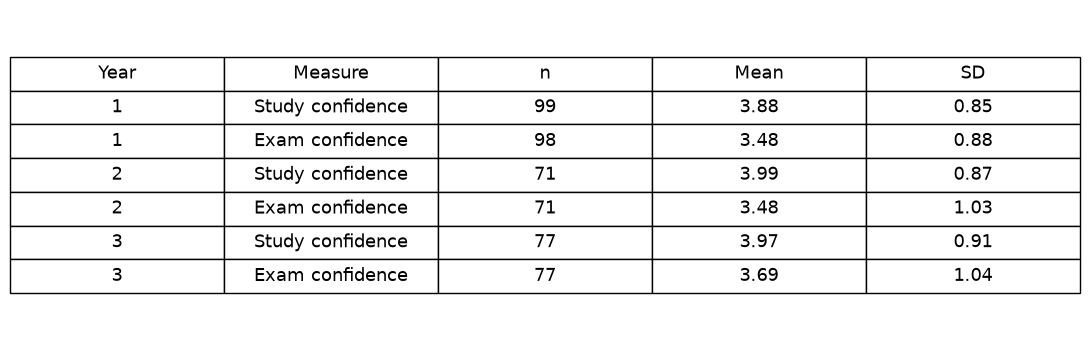

In [15]:
import matplotlib.pyplot as plt

display_table = results.copy()

display_table["Mean"] = display_table["Mean"].map("{:.2f}".format)
display_table["SD"] = display_table["SD"].map("{:.2f}".format)

fig, ax = plt.subplots(figsize=(11, 3.6))
ax.axis("off")

table = ax.table(
    cellText=display_table.values,
    colLabels=display_table.columns,
    loc="center",
    cellLoc="center"
)

table.auto_set_font_size(False)
table.set_fontsize(13)
table.scale(1, 1.7)

fig.tight_layout()

fig.savefig(
    "confidence_table.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [16]:
data.groupby("year")[
    ["Study confidence", "Exam confidence"]
].agg(["count", "mean", "std"]).round(2)

Study confidence             Exam confidence            
                count  mean   std           count  mean   std
year                                                         
1                  99  3.88  0.85              98  3.48  0.88
2                  71  3.99  0.87              71  3.48  1.03
3                  77  3.97  0.91              77  3.69  1.04

In [17]:
means = data.groupby("year")[
    ["Study confidence", "Exam confidence"]
].mean()

means

,Study confidence,Exam confidence
year,,
1,3.883838,3.479592
2,3.992958,3.478873
3,3.974026,3.688312


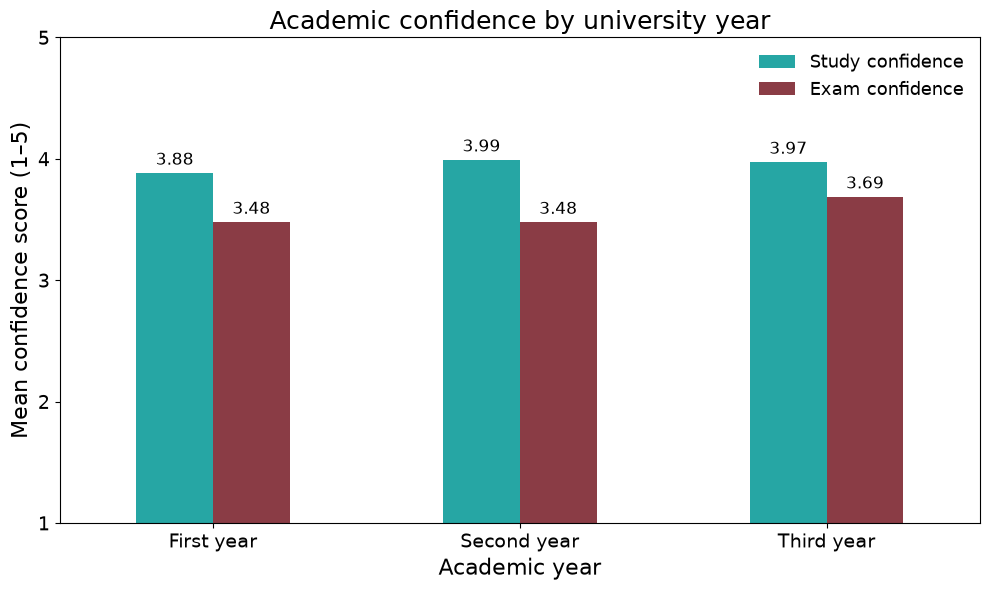

In [20]:
import matplotlib.pyplot as plt

ax = means.plot.bar(
    figsize=(10, 6),
    rot=0,
    color=["#26A6A4", "#741722D7"]
)

ax.set_title("Academic confidence by university year", fontsize=18)
ax.set_xlabel("Academic year", fontsize=16)
ax.set_ylabel("Mean confidence score (1–5)", fontsize=16)

ax.set_xticklabels(
    ["First year", "Second year", "Third year"],
    fontsize=14
)

ax.set_ylim(1, 5)
ax.set_yticks([1, 2, 3, 4, 5])
ax.tick_params(axis="y", labelsize=14)

ax.legend(fontsize=13, frameon=False)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f", padding=3, fontsize=12)

fig = ax.get_figure()
fig.tight_layout()
fig.savefig("confidence_figure.png", dpi=300, bbox_inches="tight")

plt.show()